C:\Users\Harini.S\AppData\Local\Temp\ipykernel_15840\171163329.py:7: DtypeWarning: Columns (0: Unnamed: 22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("archive/cleaned_amazon_sales.csv")


Order Status Distribution:
Status
Shipped                          77804
Shipped - Delivered to Buyer     28769
Cancelled                        18332
Shipped - Returned to Seller      1953
Shipped - Picked Up                973
Pending                            658
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipping                             8
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64

Fulfilment Type vs Order Status:
Status      Cancelled  Pending  Pending - Waiting for Pick Up  Shipped  \
Fulfilment                                                               
Amazon          11471      415                              0    77804   
Merchant         6861      243                            281        0   

Status      Shipped - Damaged  Shipped - Delivered to Buyer  \
Fulfilment                             

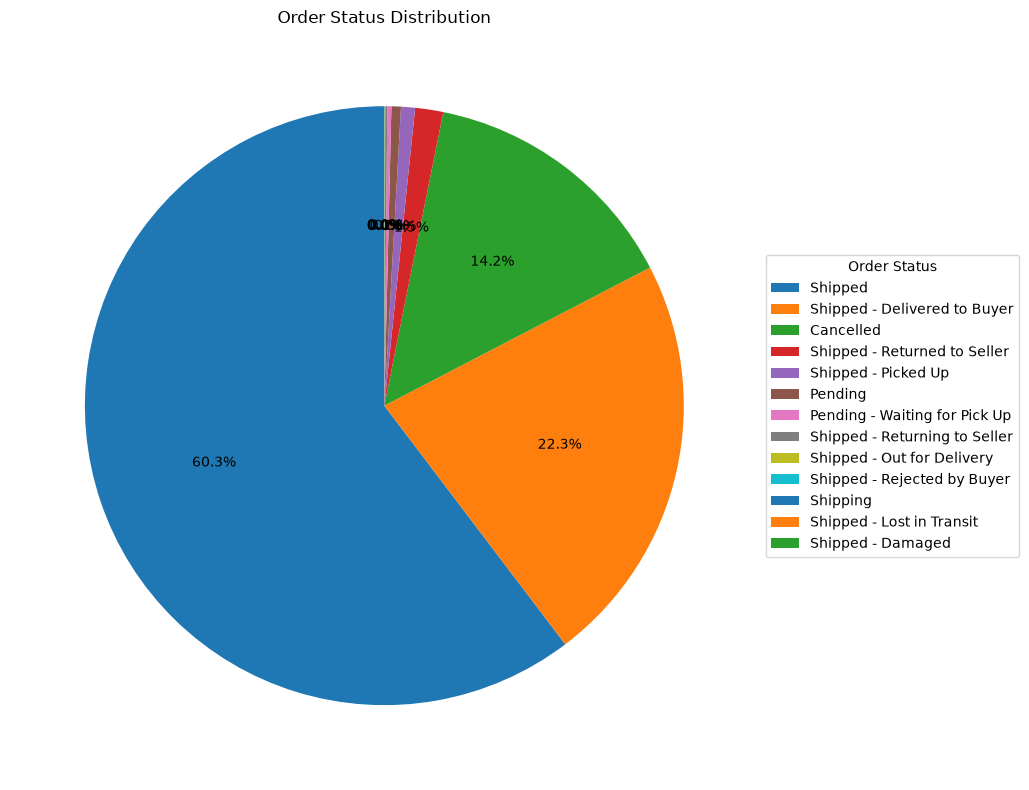

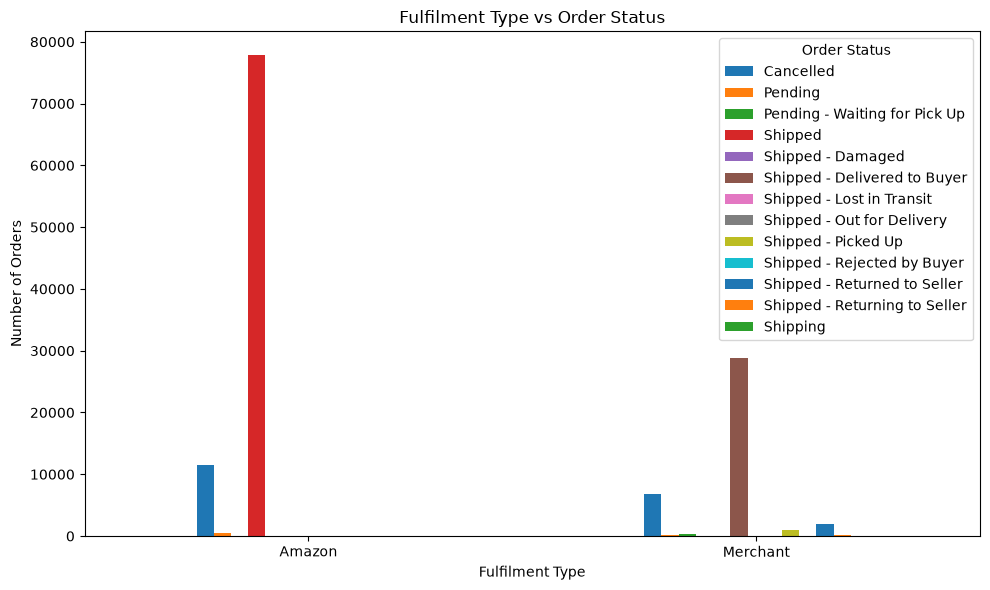

In [4]:
# Task 6: Order Status & Fulfilment Analysis

import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned dataset
df = pd.read_csv("archive/cleaned_amazon_sales.csv")


# 1. Analyze distribution of order statuses

status_distribution = df["Status"].value_counts()

print("Order Status Distribution:")
print(status_distribution)


# 2. Compare fulfilment type and cancellation rates

fulfilment_status = pd.crosstab(
    df["Fulfilment"],
    df["Status"]
)

print("\nFulfilment Type vs Order Status:")
print(fulfilment_status)


# Calculate cancellation rate for each fulfilment type

cancellation_rate = (
    df["Status"].eq("Cancelled")
    .groupby(df["Fulfilment"])
    .mean() * 100
)

print("\nCancellation Rate by Fulfilment Type:")
print(cancellation_rate)


# 3. Cancellation patterns by category

category_cancellation = pd.crosstab(
    df["Category"],
    df["Status"]
)

print("\nCancellation Pattern by Category:")
print(category_cancellation)


# 4. Cancellation patterns by state

state_cancellation = pd.crosstab(
    df["ship-state"],
    df["Status"]
)

print("\nCancellation Pattern by State:")
print(state_cancellation)

# Pie chart of order status distribution

plt.figure(figsize=(10, 8))

plt.pie(
    status_distribution.values,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Order Status Distribution")

plt.legend(
    status_distribution.index,
    title="Order Status",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.tight_layout()
plt.show()

# # 5. Pie chart of order status distribution

# plt.figure(figsize=(8, 8))

# plt.pie(
#     status_distribution.values,
#     labels=status_distribution.index,
#     autopct="%1.1f%%"
# )

# plt.title("Order Status Distribution")

# plt.show()


# 6. Grouped bar chart: Fulfilment Type vs Order Status

fulfilment_status.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Fulfilment Type vs Order Status")
plt.xlabel("Fulfilment Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.legend(title="Order Status")

plt.tight_layout()
plt.show()